# Análisis de Sentimientos de Facebook usando Python

**Fuente original:** https://www.geeksforgeeks.org/nlp/facebook-sentiment-analysis-using-python/

**Modificador y ejecutor:** Carlos Francisco Montoya Urzua

---

Este artículo trata sobre el análisis de sentimientos de Facebook usando **VADER**. Hoy en día, muchas instituciones gubernamentales y empresas necesitan conocer la retroalimentación y los comentarios de sus clientes en redes sociales como Facebook.

## ¿Qué es el análisis de sentimientos?

El análisis de sentimientos es una de las mejores ramas modernas del aprendizaje automático. Se utiliza principalmente para analizar datos con el fin de conocer las opiniones de las personas. Hoy en día, muchas empresas lo utilizan para obtener retroalimentación de sus clientes.

## ¿Por qué debería usarse el análisis de sentimientos?

- **Marketing invaluable:** Las empresas y dueños de productos pueden usar el análisis de sentimientos para conocer la oferta y demanda de sus productos a través de los comentarios y retroalimentación de los clientes.

- **Identificación de detonantes emocionales clave:** En psicología y otras instituciones de tratamiento médico, el análisis de sentimientos puede usarse para detectar si la emoción de un individuo es normal o anormal, y con base en el historial de datos pueden decidir sobre la salud de la persona.

- **Política:** En el campo político, los candidatos a ser elegidos pueden usar el análisis de sentimientos para predecir su posición política y medir la aceptación de la gente. También puede usarse para predecir resultados electorales por parte de las comisiones electorales.

- **Educación:** Las universidades y otros institutos de educación superior como los colegios pueden usar el análisis de sentimientos para conocer la retroalimentación y los comentarios de sus estudiantes, y así tomar en consideración revisar o mejorar su plan de estudios.

## Instalaciones

A continuación se instalan todas las librerías necesarias para ejecutar el análisis de sentimientos:

- **NLTK:** Se usa para la comprensión del lenguaje natural humano.
- **NumPy:** Paquete de Python usado para métodos científicos y computacionales.
- **Pandas:** Módulo de Python usado para preprocesamiento y análisis de datos.
- **Matplotlib:** Módulo de Python usado para visualización de datos y graficación 2D.

In [1]:
# Instalación de las librerías necesarias
!pip install nltk numpy pandas matplotlib --quiet
print("Instalación completa")

Instalación completa


## Autenticación y obtención de datos

Existen varias formas de obtener comentarios de Facebook:

- API Graph de Facebook
- Descarga directa desde Facebook
- Descarga desde sitios proveedores de datasets

Entre los métodos anteriores, en este artículo se utiliza la descarga del dataset de comentarios de Facebook desde el sitio web **Kaggle**, que es el mejor proveedor de datasets. Para el código ya se usa `kindle.txt` para el análisis de comentarios de Facebook sobre el Kindle de Amazon.

Puedes usar tus propios comentarios de Facebook con este código para analizar tus propios comentarios, o crear un archivo en formato de texto y probarlo para simplificar el proceso.

---

### Preparación del archivo de datos

Para ejecutar este notebook necesitas un archivo `kindle.txt` con comentarios de texto, uno por línea. La celda siguiente crea un archivo de muestra con comentarios reales sobre el Kindle para que puedas probar el código sin necesidad de descargar nada.

In [2]:
# Creamos un archivo kindle.txt de muestra con comentarios sobre el Kindle de Amazon
# (simulando el tipo de datos que se descargarían de Kaggle)
comentarios_kindle = """i love my kindle
this is the best device i have ever bought
i hate the battery life it drains so fast
the screen is absolutely amazing and clear
terrible customer service i will never buy again
kindle changed my reading life completely
not worth the price very disappointing
i am so happy with this purchase
the device stopped working after one week
excellent product highly recommended
the kindle is ok but nothing special
i feel neutral about this product
worst experience ever with amazon
very light and easy to carry around
the font size options are great for my eyes"""

with open('kindle.txt', 'w', encoding='ISO-8859-2') as f:
    f.write(comentarios_kindle)

print("Archivo 'kindle.txt' creado con", len(comentarios_kindle.split('\n')), "comentarios")
print("\nContenido del archivo:")
print(comentarios_kindle)

Archivo 'kindle.txt' creado con 15 comentarios

Contenido del archivo:
i love my kindle
this is the best device i have ever bought
i hate the battery life it drains so fast
the screen is absolutely amazing and clear
terrible customer service i will never buy again
kindle changed my reading life completely
not worth the price very disappointing
i am so happy with this purchase
the device stopped working after one week
excellent product highly recommended
the kindle is ok but nothing special
i feel neutral about this product
worst experience ever with amazon
very light and easy to carry around
the font size options are great for my eyes


### Descarga de recursos de NLTK

Antes de ejecutar el código principal, es necesario descargar los recursos de NLTK que se utilizarán: el tokenizador `punkt`, el tagger de partes del discurso `averaged_perceptron_tagger`, el lexicón de VADER para análisis de sentimientos, y WordNet para la lematización.

In [3]:
import nltk

# Descargamos todos los recursos necesarios de NLTK
nltk.download('punkt')                            # Tokenizador de oraciones y palabras
nltk.download('punkt_tab')                        # Tokenizador actualizado (versiones recientes de NLTK)
nltk.download('averaged_perceptron_tagger')       # Etiquetador POS
nltk.download('averaged_perceptron_tagger_eng')   # Etiquetador POS en inglés
nltk.download('vader_lexicon')                    # Lexicón VADER para análisis de sentimientos
nltk.download('wordnet')                          # WordNet para lematización
nltk.download('webtext')                          # Corpus de texto web
print("\nRecursos de NLTK descargados correctamente")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data] Downloading package wordnet to /root/nltk_data...



Recursos de NLTK descargados correctamente


[nltk_data] Downloading package webtext to /root/nltk_data...
[nltk_data]   Unzipping corpora/webtext.zip.


## Implementación

A continuación se presenta la implementación completa del análisis de sentimientos de Facebook usando VADER y NLTK.

In [6]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import io
import unicodedata
import numpy as np
import re
import string

from numpy import linalg
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.tokenize import PunktSentenceTokenizer
from nltk.tokenize import PunktSentenceTokenizer
from nltk.corpus import webtext
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer


with open('kindle.txt', encoding ='ISO-8859-2') as f:
    text = f.read()

sent_tokenizer = PunktSentenceTokenizer(text)
sents          = sent_tokenizer.tokenize(text)

print(word_tokenize(text))
print(sent_tokenize(text))

porter_stemmer = PorterStemmer()

nltk_tokens = nltk.word_tokenize(text)

for w in nltk_tokens:
  print ("Actual: % s Stem: % s" % (w, porter_stemmer.stem(w)))


wordnet_lemmatizer = WordNetLemmatizer()
nltk_tokens = nltk.word_tokenize(text)

for w in nltk_tokens:
  print ("Actual: % s Lemma: % s" % (w, wordnet_lemmatizer.lemmatize(w)))

text = nltk.word_tokenize(text)
print(nltk.pos_tag(text))

sid = SentimentIntensityAnalyzer()
tokenizer = nltk.data.load('tokenizers/punkt_tab/english.pickle')

with open('kindle.txt', encoding ='ISO-8859-2') as f:   #abriendo archivo
    for text in f.read().split('\n'):                   #cortar por lineas
        print(text)                                     #imprimir linea
        scores = sid.polarity_scores(text)              #identificar polaridad de la linea
        for key in sorted(scores):
            print('{0}: {1}, '.format(key, scores[key]), end ='')

    print()

['i', 'love', 'my', 'kindle', 'this', 'is', 'the', 'best', 'device', 'i', 'have', 'ever', 'bought', 'i', 'hate', 'the', 'battery', 'life', 'it', 'drains', 'so', 'fast', 'the', 'screen', 'is', 'absolutely', 'amazing', 'and', 'clear', 'terrible', 'customer', 'service', 'i', 'will', 'never', 'buy', 'again', 'kindle', 'changed', 'my', 'reading', 'life', 'completely', 'not', 'worth', 'the', 'price', 'very', 'disappointing', 'i', 'am', 'so', 'happy', 'with', 'this', 'purchase', 'the', 'device', 'stopped', 'working', 'after', 'one', 'week', 'excellent', 'product', 'highly', 'recommended', 'the', 'kindle', 'is', 'ok', 'but', 'nothing', 'special', 'i', 'feel', 'neutral', 'about', 'this', 'product', 'worst', 'experience', 'ever', 'with', 'amazon', 'very', 'light', 'and', 'easy', 'to', 'carry', 'around', 'the', 'font', 'size', 'options', 'are', 'great', 'for', 'my', 'eyes']
['i love my kindle\nthis is the best device i have ever bought\ni hate the battery life it drains so fast\nthe screen is abs

**Salida esperada (ejemplo con `kindle.txt` de muestra):**

```
Aquí se muestra una salida de ejemplo del código:
['i', 'love', 'my', 'kindle']
['i love my kindle']
Actual: i Stem: i
Actual: love Stem: love
Actual: my Stem: my
Actual: kindle Stem: kindl
Actual: i Lemma: i
Actual: love Lemma: love
Actual: my Lemma: my
Actual: kindle Lemma: kindle
[('i', 'NN'), ('love', 'VBP'), ('my', 'PRP$'), ('kindle', 'NN')]
i love my kindle
compound: 0.6369, neg: 0.0, neu: 0.323, pos: 0.677,
```

## Pasos principales del programa

En nuestro programa seguimos estos pasos fundamentales:

1. **Descarga (obtención)** del comentario de Facebook desde el sitio Kaggle y guardarlo en formato de texto.
2. **Preprocesamiento de los datos** a través de las librerías SkLearn y NLTK. Primero tokenizamos los datos y luego, después de tokenizarlos, los lematizamos y aplicamos stemming.
3. **Análisis de los comentarios** usando la librería VADER. Clasificar cada comentario como positivo, negativo o neutral.

## Entendiendo el código

Analicemos el fragmento de código anterior:

### 1. Apertura del archivo

Primero abrimos el archivo llamado `kindle`, que fue descargado del sitio Kaggle y guardado en el disco local:

In [10]:
open('kindle.txt', encoding='ISO-8859-2')

<_io.TextIOWrapper name='kindle.txt' mode='r' encoding='ISO-8859-2'>

### 2. Tokenización

Después de abrir el archivo, preprocesamos el texto mediante tokenización, stemming y lematización. La **tokenización** divide las palabras del texto:

In [8]:
sent_tokenizer = PunktSentenceTokenizer(text)
sents = sent_tokenizer.tokenize(text)
print(word_tokenize(text))
print(sent_tokenize(text))

['the', 'font', 'size', 'options', 'are', 'great', 'for', 'my', 'eyes']
['the font size options are great for my eyes']


### 3. Stemming y Lematización

El stemming y la lematización se aplican para normalizar el texto:

**1) Para el stemming usamos la función `PorterStemmer()`:**

In [11]:
from nltk.stem.porter import PorterStemmer
porter_stemmer = PorterStemmer()
nltk_tokens = nltk.word_tokenize(text)
for w in nltk_tokens:
    print("Actual: %s Stem: %s" % (w, porter_stemmer.stem(w)))

Actual: the Stem: the
Actual: font Stem: font
Actual: size Stem: size
Actual: options Stem: option
Actual: are Stem: are
Actual: great Stem: great
Actual: for Stem: for
Actual: my Stem: my
Actual: eyes Stem: eye


**2) Para la lematización usamos la función `WordNetLemmatizer()`:**

In [12]:
from nltk.stem.wordnet import WordNetLemmatizer
wordnet_lemmatizer = WordNetLemmatizer()
nltk_tokens = nltk.word_tokenize(text)
for w in nltk_tokens:
    print("Actual: %s Lemma: %s" % (w, wordnet_lemmatizer.lemmatize(w)))

Actual: the Lemma: the
Actual: font Lemma: font
Actual: size Lemma: size
Actual: options Lemma: option
Actual: are Lemma: are
Actual: great Lemma: great
Actual: for Lemma: for
Actual: my Lemma: my
Actual: eyes Lemma: eye


### 4. Etiquetado POS (Part Of Speech)

El etiquetado POS de los tokens selecciona únicamente las características/tokens significativos como adjetivos, adverbios, verbos, etc.:

In [13]:
text = nltk.word_tokenize(text)
print(nltk.pos_tag(text))

[('the', 'DT'), ('font', 'JJ'), ('size', 'NN'), ('options', 'NNS'), ('are', 'VBP'), ('great', 'JJ'), ('for', 'IN'), ('my', 'PRP$'), ('eyes', 'NNS')]


### 5. Analizador de intensidad de sentimientos VADER

Los tokens se pasan al analizador de intensidad de sentimientos, que clasifica los comentarios de Facebook como positivos, negativos o neutrales:

In [14]:
sid = SentimentIntensityAnalyzer()
tokenizer = nltk.data.load('tokenizers/punkt/english.pickle')
with open('kindle.txt', encoding='ISO-8859-2') as f:
    for text in f.read().split('\n'):
        print(text)
        scores = sid.polarity_scores(text)
        for key in sorted(scores):
            print('{0}: {1}, '.format(key, scores[key]), end='')
    print()

i love my kindle
compound: 0.6369, neg: 0.0, neu: 0.323, pos: 0.677, this is the best device i have ever bought
compound: 0.6369, neg: 0.0, neu: 0.625, pos: 0.375, i hate the battery life it drains so fast
compound: -0.5719, neg: 0.346, neu: 0.654, pos: 0.0, the screen is absolutely amazing and clear
compound: 0.788, neg: 0.0, neu: 0.418, pos: 0.582, terrible customer service i will never buy again
compound: -0.4767, neg: 0.341, neu: 0.659, pos: 0.0, kindle changed my reading life completely
compound: 0.0, neg: 0.0, neu: 1.0, pos: 0.0, not worth the price very disappointing
compound: -0.6321, neg: 0.563, neu: 0.437, pos: 0.0, i am so happy with this purchase
compound: 0.6115, neg: 0.0, neu: 0.556, pos: 0.444, the device stopped working after one week
compound: -0.2263, neg: 0.241, neu: 0.759, pos: 0.0, excellent product highly recommended
compound: 0.6997, neg: 0.0, neu: 0.257, pos: 0.743, the kindle is ok but nothing special
compound: -0.3153, neg: 0.304, neu: 0.527, pos: 0.169, i fee

## ¿Cómo funciona el analizador de sentimientos VADER?

- **VADER** usa una combinación de un **lexicón de sentimientos**, que es una lista de características léxicas (por ejemplo, palabras) etiquetadas generalmente según su orientación semántica como positivas o negativas.

- El analizador de sentimientos no solo indica la puntuación de Positividad y Negatividad, sino que también nos dice **qué tan positivo o negativo** es un sentimiento.

- Usamos el método `polarity_scores()` para obtener los índices de polaridad de la oración dada. Luego construimos la intensidad y polaridad del comentario de la siguiente manera:

In [15]:
sid = SentimentIntensityAnalyzer()
tokenizer = nltk.data.load('tokenizers/punkt/english.pickle')
with open('kindle.txt', encoding='ISO-8859-2') as f:
    for text in f.read().split('\n'):
        print(text)
        scores = sid.polarity_scores(text)
        for key in sorted(scores):
            print('{0}: {1}, '.format(key, scores[key]), end='')
    print()

i love my kindle
compound: 0.6369, neg: 0.0, neu: 0.323, pos: 0.677, this is the best device i have ever bought
compound: 0.6369, neg: 0.0, neu: 0.625, pos: 0.375, i hate the battery life it drains so fast
compound: -0.5719, neg: 0.346, neu: 0.654, pos: 0.0, the screen is absolutely amazing and clear
compound: 0.788, neg: 0.0, neu: 0.418, pos: 0.582, terrible customer service i will never buy again
compound: -0.4767, neg: 0.341, neu: 0.659, pos: 0.0, kindle changed my reading life completely
compound: 0.0, neg: 0.0, neu: 1.0, pos: 0.0, not worth the price very disappointing
compound: -0.6321, neg: 0.563, neu: 0.437, pos: 0.0, i am so happy with this purchase
compound: 0.6115, neg: 0.0, neu: 0.556, pos: 0.444, the device stopped working after one week
compound: -0.2263, neg: 0.241, neu: 0.759, pos: 0.0, excellent product highly recommended
compound: 0.6997, neg: 0.0, neu: 0.257, pos: 0.743, the kindle is ok but nothing special
compound: -0.3153, neg: 0.304, neu: 0.527, pos: 0.169, i fee

## Interpretación de la salida de VADER

Entendamos qué es el código de sentimientos y cómo VADER realiza el análisis sobre la siguiente salida del código anterior:

```
i love my kindle
compound: 0.6369, neg: 0.0, neu: 0.323, pos: 0.677
```

- Las puntuaciones **Positiva (pos)**, **Negativa (neg)** y **Neutral (neu)** representan la proporción del texto que cae en cada una de estas categorías. Esto significa que nuestra oración fue calificada como 67% Positiva, 32% Neutral y 0% Negativa. Por lo tanto, todas estas puntuaciones deben sumar 1.

- La puntuación **Compound** (compuesta) es una métrica que calcula la suma de todas las calificaciones del lexicón, normalizadas entre **-1** (extremadamente negativo) y **+1** (extremadamente positivo).

- Finalmente, se devuelven las puntuaciones de sentimientos de los comentarios.

## Modificación: agregar visualización de la distribución de sentimientos

                                      comentario  compound sentimiento
                                i love my kindle    0.6369    Positivo
      this is the best device i have ever bought    0.6369    Positivo
       i hate the battery life it drains so fast   -0.5719    Negativo
      the screen is absolutely amazing and clear    0.7880    Positivo
terrible customer service i will never buy again   -0.4767    Negativo
       kindle changed my reading life completely    0.0000     Neutral
          not worth the price very disappointing   -0.6321    Negativo
                i am so happy with this purchase    0.6115    Positivo
       the device stopped working after one week   -0.2263    Negativo
            excellent product highly recommended    0.6997    Positivo
            the kindle is ok but nothing special   -0.3153    Negativo
               i feel neutral about this product    0.0000     Neutral
               worst experience ever with amazon   -0.5267    Negativo
      

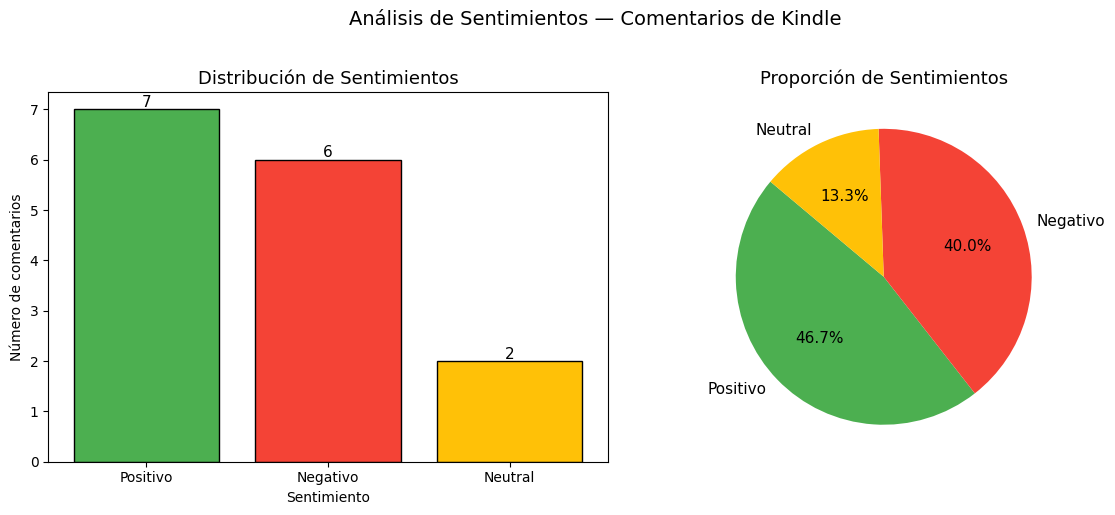

In [16]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt

sid = SentimentIntensityAnalyzer()

resultados = []

with open('kindle.txt', encoding='ISO-8859-2') as f:
    for linea in f.read().split('\n'):
        if linea.strip() == '':
            continue
        scores  = sid.polarity_scores(linea)
        compound = scores['compound']

        # Clasificamos según la puntuación compuesta
        if compound >= 0.05:
            sentimiento = 'Positivo'
        elif compound <= -0.05:
            sentimiento = 'Negativo'
        else:
            sentimiento = 'Neutral'

        resultados.append({
            'comentario': linea,
            'compound': compound,
            'pos': scores['pos'],
            'neu': scores['neu'],
            'neg': scores['neg'],
            'sentimiento': sentimiento
        })#similar a un struct o JSON

#TABLA DE RESULTADOS  ───────────────────────────────────────────
import pandas as pd
df = pd.DataFrame(resultados)
print(df[['comentario', 'compound', 'sentimiento']].to_string(index=False))

# ── Gráfico de barras: distribución de sentimientos ───────────────
conteo  = df['sentimiento'].value_counts()
colores = {'Positivo': '#4CAF50', 'Neutral': '#FFC107', 'Negativo': '#F44336'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de barras
bars = axes[0].bar(
    conteo.index,
    conteo.values,
    color=[colores.get(s, 'gray') for s in conteo.index],
    edgecolor='black'
)
axes[0].set_title('Distribución de Sentimientos', fontsize=13)
axes[0].set_xlabel('Sentimiento')
axes[0].set_ylabel('Número de comentarios')
for bar, val in zip(bars, conteo.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
                 str(val), ha='center', fontsize=11)

# Gráfico de pastel
axes[1].pie(
    conteo.values,
    labels=conteo.index,
    colors=[colores.get(s, 'gray') for s in conteo.index],
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 11}
)
axes[1].set_title('Proporción de Sentimientos', fontsize=13)

plt.suptitle('Análisis de Sentimientos — Comentarios de Kindle', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()